# T15. Recorridos: distancia, duración, velocidad, rodeo y radios de acceso

**Objetivo.** Describir cómo son los viajes y medir cuánto cuesta andar hasta una estación y desde ella para cada radio de acceso.

**Valor para el proyecto.** Confirma o ajusta los radios del barrido de la fase 1 (al empezar, 200, 300 y 400 m), da el factor de rodeo con el que se pasa de distancia en línea recta a distancia andando y dice qué parte de la demanda deja de tener sentido con estaciones.

Viajes elegibles del periodo de ajuste (1–21/02).

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
FRANJAS = CFG["exploracion"]["franjas_horarias"]
RADIOS_PLAN = CFG["movilidad"]["radios_acceso_m"]

PARAMETROS = {
    "percentiles": [5, 25, 50, 75, 95, 99],
    # Rodeo: solo viajes con línea recta suficiente para que el error del GPS no domine el cociente.
    "rodeo_dist_recta_min_m": 200,
    # Viaje circular: vuelve casi al punto de partida tras recorrer una distancia apreciable.
    "circular_dist_recta_max_m": 100,
    "circular_dis_min_m": 500,
    # Radios de acceso a pie a explorar (m).
    "radios_m": [150, 200, 250, 300, 400, 500],
    # Velocidad a pie (hipótesis, justificada en config.yaml).
    "velocidad_pie_ms": CFG["movilidad"]["velocidad_pie_ms"],
}
TITULO_AJUSTE = "viajes elegibles del periodo de ajuste (1–21/02/2021)"
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
CMAP_SECUENCIAL = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])


def guardar_tabla(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", index=False, lineterminator="\n")


def tabla_indicadores(resumen):
    """Tabla indicador/valor que conserva los enteros como enteros en el CSV."""
    return pd.DataFrame({"indicador": list(resumen), "valor": pd.Series(list(resumen.values()), dtype=object)})


def franja(hora):
    etiqueta = pd.Series(pd.NA, index=hora.index, dtype="string")
    for nombre, (inicio, fin) in FRANJAS.items():
        etiqueta[(hora >= inicio) & (hora < fin)] = nombre
    assert etiqueta.notna().all()
    return etiqueta


v = cargar_viajes(periodo="ajuste")
v["dist_recta_m"] = haversine_m(v["latO"], v["lonO"], v["latD"], v["lonD"])
v["rodeo"] = np.where(v["dist_recta_m"] >= PARAMETROS["rodeo_dist_recta_min_m"],
                      v["dis_m"] / v["dist_recta_m"].clip(lower=1e-9), np.nan)
v["franja"] = franja(v["tsO"].dt.hour)
v["tipo_dia"] = np.where(v["tsO"].dt.day_of_week >= 5, "fin_de_semana", "laborable")
print(f"{len(v)} viajes elegibles en el periodo de ajuste")

16756 viajes elegibles en el periodo de ajuste


## 1. Distancia, duración y velocidad

**Qué queremos ver.** Las distribuciones de `dis_m`, `tt_s` y `vel_kmh`, con escala logarítmica donde la cola es larga, y sus percentiles.

**Por qué importa.** El tamaño típico de un viaje fija con qué radios de acceso merece la pena usar el servicio y entra en el consumo por viaje (T16).

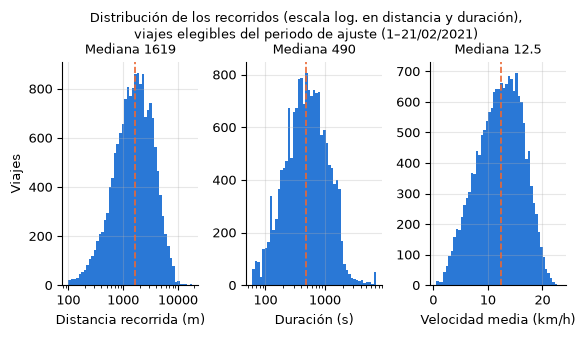

,variable,unidad,viajes,media,min,p5,p25,p50,p75,p95,p99,max
0,dis_m,m,16756,2054.821,100.566,348.527,895.636,1619.397,2793.595,5186.718,7466.717,18267.976
1,tt_s,s,16756,672.194,60.000,121.000,279.000,490.000,860.000,1699.000,2978.550,7241.000
2,vel_kmh,km/h,16756,12.192,0.517,4.992,9.275,12.460,15.315,18.488,20.311,23.180
3,dist_recta_m,m,16756,1239.258,0.333,106.872,497.008,947.281,1707.981,3307.076,4805.562,8623.008
4,rodeo,-,15258,1.880,1.000,1.054,1.185,1.329,1.654,4.567,11.403,46.237


In [2]:
filas = []
for col, unidad in [("dis_m", "m"), ("tt_s", "s"), ("vel_kmh", "km/h"), ("dist_recta_m", "m"), ("rodeo", "-")]:
    x = v[col].dropna()
    fila = {"variable": col, "unidad": unidad, "viajes": len(x), "media": x.mean(), "min": x.min()}
    for p in PARAMETROS["percentiles"]:
        fila[f"p{p}"] = x.quantile(p / 100)
    fila["max"] = x.max()
    filas.append(fila)
distribuciones = pd.DataFrame(filas)
numericas = distribuciones.columns.drop(["variable", "unidad", "viajes"])
distribuciones[numericas] = distribuciones[numericas].astype(float).round(3)
guardar_tabla(distribuciones, "T15_distribuciones")

paneles = [("dis_m", "Distancia recorrida (m)", True), ("tt_s", "Duración (s)", True),
           ("vel_kmh", "Velocidad media (km/h)", False)]
histogramas = {}
fig, ejes = plt.subplots(1, 3, figsize=(6.5, 2.9))
fig.subplots_adjust(wspace=0.35)
for eje, (col, etiqueta, log) in zip(ejes, paneles):
    x = v[col]
    bordes = np.logspace(np.log10(x.min()), np.log10(x.max()), 50) if log else np.linspace(x.min(), x.max(), 51)
    cuentas, _, _ = eje.hist(x, bins=bordes, color=AZUL)
    if log:
        eje.set_xscale("log")
        eje.xaxis.set_major_formatter(FuncFormatter(lambda val, _: f"{val:g}"))
    mediana = x.median()
    eje.axvline(mediana, color=NARANJA, lw=1.2, ls="--")
    eje.set_title(f"Mediana {mediana:.0f}" if col != "vel_kmh" else f"Mediana {mediana:.1f}", fontsize=9)
    eje.set_xlabel(etiqueta)
    histogramas[col] = {"bordes": np.round(bordes, 3), "viajes": cuentas.astype(int), "mediana": mediana,
                        "escala_log": log}
ejes[0].set_ylabel("Viajes")
fig.suptitle(f"Distribución de los recorridos (escala log. en distancia y duración),\n{TITULO_AJUSTE}",
             fontsize=9, y=1.06)
guardar_figura(fig, TEMA, "T15_distribuciones")

exportar(FASE, "t15_distribuciones", {"histogramas": histogramas, "tabla": distribuciones})
display(distribuciones)

**Conclusiones.**

- El viaje mediano recorre 1 619 m en 490 s (unos 8 min) a 12,5 km/h. El 95 % recorre menos de 5 187 m y dura menos de 1 699 s.
- La distancia en línea recta mediana es de 947 m: los viajes son cortos comparados con un radio de acceso de 300–400 m por extremo.

## 2. Rodeo y viajes circulares

**Qué queremos ver.** El cociente entre la distancia recorrida y la distancia en línea recta (viajes con línea recta de 200 m o más) y cuántos viajes vuelven casi al punto de partida (línea recta < 100 m y `dis_m` ≥ 500 m).

**Por qué importa.** El rodeo sirve después para pasar de distancia en línea recta a distancia andando aproximada. Los viajes circulares, con estaciones, empezarían y acabarían en la misma.

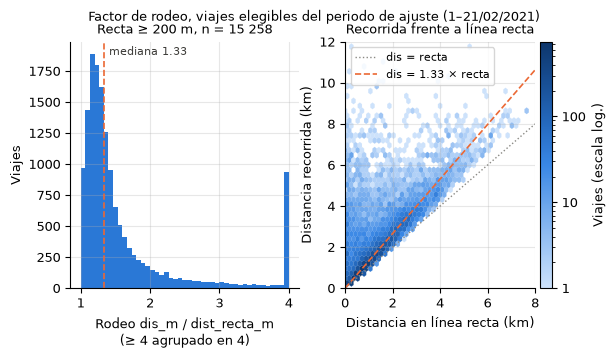

,valor
viajes,16756.000
viajes_con_rodeo,15258.000
rodeo_mediana,1.329
rodeo_p25,1.185
rodeo_p75,1.654
rodeo_p95,4.567
pct_rodeo_menor_1,0.050
viajes_circulares,602.000
pct_viajes_circulares,3.590
viajes_dist_recta_menor_100_m,796.000


In [3]:
p = PARAMETROS
r = v["rodeo"].dropna()
circular = (v["dist_recta_m"] < p["circular_dist_recta_max_m"]) & (v["dis_m"] >= p["circular_dis_min_m"])
indicadores = {
    "viajes": len(v),
    "viajes_con_rodeo": len(r),
    "rodeo_mediana": round(float(r.median()), 3),
    "rodeo_p25": round(float(r.quantile(0.25)), 3),
    "rodeo_p75": round(float(r.quantile(0.75)), 3),
    "rodeo_p95": round(float(r.quantile(0.95)), 3),
    "pct_rodeo_menor_1": round(float(100 * (r < 1).mean()), 2),
    "viajes_circulares": int(circular.sum()),
    "pct_viajes_circulares": round(float(100 * circular.mean()), 2),
    "viajes_dist_recta_menor_100_m": int((v["dist_recta_m"] < p["circular_dist_recta_max_m"]).sum()),
}
RODEO = indicadores["rodeo_mediana"]

fig, ejes = plt.subplots(1, 2, figsize=(6.5, 3.2))
eje = ejes[0]
tope = 4
bordes = np.linspace(1, tope, 46)
cuentas, _, _ = eje.hist(r.clip(upper=tope), bins=bordes, color=AZUL)
eje.axvline(RODEO, color=NARANJA, lw=1.2, ls="--")
eje.annotate(f"mediana {RODEO:.2f}", (RODEO, 1), xycoords=("data", "axes fraction"), xytext=(4, -3),
             textcoords="offset points", va="top", fontsize=8, color="#3d3c39")
eje.set_xlabel(f"Rodeo dis_m / dist_recta_m\n(≥ {tope} agrupado en {tope})")
eje.set_ylabel("Viajes")
n_txt = f"{len(r):,}".replace(",", " ")
eje.set_title(f"Recta ≥ {p['rodeo_dist_recta_min_m']} m, n = {n_txt}", fontsize=9)

eje = ejes[1]
hb = eje.hexbin(v["dist_recta_m"] / 1000, v["dis_m"] / 1000, gridsize=45, bins="log", cmap=CMAP_SECUENCIAL,
                mincnt=1, extent=(0, 8, 0, 12), linewidths=0.1)
x = np.array([0, 8])
eje.plot(x, x, color=GRIS, lw=1, ls=":", label="dis = recta")
eje.plot(x, RODEO * x, color=NARANJA, lw=1.2, ls="--", label=f"dis = {RODEO:.2f} × recta")
eje.set_xlim(0, 8)
eje.set_ylim(0, 12)
eje.set_xlabel("Distancia en línea recta (km)")
eje.set_ylabel("Distancia recorrida (km)")
eje.legend(loc="upper left")
barra = fig.colorbar(hb, ax=eje, pad=0.02)
barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda val, _: f"{val:g}"))
barra.set_label("Viajes (escala log.)")
eje.set_title("Recorrida frente a línea recta", fontsize=9)
fig.suptitle(f"Factor de rodeo, {TITULO_AJUSTE}", fontsize=9)
guardar_figura(fig, TEMA, "T15_rodeo")

# Para la web, una rejilla de 0,25 km con el número de viajes (recta frente a recorrida).
rejilla, bx, by = np.histogram2d(v["dist_recta_m"] / 1000, v["dis_m"] / 1000, bins=[32, 48], range=[[0, 8], [0, 12]])
exportar(FASE, "t15_rodeo", {
    "histograma": {"bordes": np.round(bordes, 3), "viajes": cuentas.astype(int), "tope": tope},
    "rejilla": {"recta_km": np.round(bx, 3), "recorrida_km": np.round(by, 3), "viajes": rejilla.astype(int)},
    "indicadores": indicadores,
})
display(pd.Series(indicadores).to_frame("valor"))

**Conclusiones.**

- El rodeo mediano es **1,329** (P25 1,185, P75 1,654) en 15 258 viajes. La cola larga (P95 4,57) son paseos, no desplazamientos directos. Se usa 1,329 como hipótesis para la distancia andando.
- Hay 602 viajes circulares, el **3,59 %**: con estaciones empezarían y acabarían en la misma, y el simulador debe admitirlo.

## 3. Medianas por franja y tipo de día

**Qué queremos ver.** Mediana de distancia, duración y velocidad en cada franja horaria de laborables y fines de semana.

**Por qué importa.** Si los viajes cambian mucho de una franja a otra, el radio aceptable y el consumo por viaje también cambian.

In [4]:
orden = {nombre: i for i, nombre in enumerate(FRANJAS)}
filas = []
for tipo in ["laborable", "fin_de_semana"]:
    sub = v[v["tipo_dia"] == tipo]
    grupos = [(f, g) for f, g in sub.groupby("franja")] + [("todas", sub)]
    for nombre, g in sorted(grupos, key=lambda x: orden.get(x[0], len(orden))):
        fila = {"tipo_dia": tipo, "franja": nombre, "viajes": len(g)}
        for c in ["dis_m", "tt_s", "vel_kmh", "dist_recta_m"]:
            fila[f"{c}_mediana"] = round(float(g[c].median()), 2)
        filas.append(fila)
medianas = pd.DataFrame(filas)
guardar_tabla(medianas, "T15_medianas_franja_tipo_dia")
exportar(FASE, "t15_medianas", medianas)
display(medianas)

,tipo_dia,franja,viajes,dis_m_mediana,tt_s_mediana,vel_kmh_mediana,dist_recta_m_mediana
0,laborable,madrugada,115,1694.79,390.0,15.16,1313.12
1,laborable,punta_manana,1721,1572.10,424.0,13.75,1174.35
2,laborable,mediodia,4219,1636.79,471.0,12.93,994.29
3,laborable,punta_tarde,4562,1700.89,521.0,11.97,920.76
4,laborable,noche,1378,1477.14,430.0,13.52,851.71
5,laborable,todas,11995,1636.79,480.0,12.81,985.42
6,fin_de_semana,madrugada,36,1443.72,465.0,13.90,1060.23
7,fin_de_semana,punta_manana,207,1287.21,359.0,14.55,918.56
8,fin_de_semana,mediodia,1779,1544.32,519.0,11.16,891.63
9,fin_de_semana,punta_tarde,2058,1691.82,570.0,10.93,822.29


**Conclusiones.**

- Los viajes son parecidos en todas las franjas: la mediana de distancia se mueve entre 1 287 y 1 701 m, y el fin de semana es algo más lento (11,42 km/h frente a 12,81 en laborable).
- No hace falta un radio distinto por franja.

## 4. Radios de acceso

**Qué queremos ver.** Para R = 150 a 500 m, el porcentaje de viajes en los que andar hasta la estación y desde ella tarda más que el propio viaje (caso peor: R en cada extremo; caso medio: 2R/3) y el porcentaje con `dis_m` ≤ 2R. Distancias a pie con el rodeo y a 1,3 m/s.

**Por qué importa.** Con estaciones, cada viaje paga el acceso a pie. Si ese coste supera el viaje, el usuario no usaría el servicio. Fija los radios del barrido.

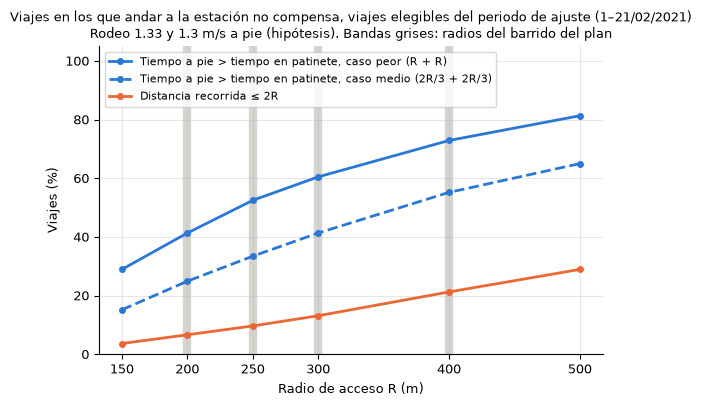

radio_m,150,200,250,300,400,500
radio_del_plan,False,True,True,True,True,False
dist_pie_peor_m,398.7,531.6,664.5,797.4,1063.2,1329.0
t_pie_peor_s,306.7,408.9,511.2,613.4,817.8,1022.3
pct_t_pie_supera_viaje_peor,28.91,41.31,52.46,60.45,72.87,81.3
pct_andar_directo_mas_rapido_peor,36.3,43.57,49.96,56.05,66.08,73.28
dist_pie_medio_m,265.8,354.4,443.0,531.6,708.8,886.0
t_pie_medio_s,204.5,272.6,340.8,408.9,545.2,681.5
pct_t_pie_supera_viaje_medio,15.15,24.89,33.41,41.31,55.17,64.98
pct_andar_directo_mas_rapido_medio,29.57,34.12,38.57,43.57,52.25,59.63
pct_dis_le_2R,3.65,6.62,9.64,13.11,21.23,28.91


In [5]:
# Caso peor: R en cada extremo. Caso medio: 2R/3 en cada extremo (distancia media al centro
# de un círculo de radio R con puntos repartidos uniformemente). Ambas se multiplican por el
# rodeo y se pasan a tiempo con la velocidad a pie.
vel = PARAMETROS["velocidad_pie_ms"]
t_directo = RODEO * v["dist_recta_m"] / vel  # andar todo el trayecto
filas = []
for radio in PARAMETROS["radios_m"]:
    fila = {"radio_m": radio, "radio_del_plan": radio in RADIOS_PLAN}
    for caso, dist in [("peor", 2 * radio), ("medio", 2 * 2 * radio / 3)]:
        d_pie = RODEO * dist
        t_pie = d_pie / vel
        fila[f"dist_pie_{caso}_m"] = round(d_pie, 1)
        fila[f"t_pie_{caso}_s"] = round(t_pie, 1)
        fila[f"pct_t_pie_supera_viaje_{caso}"] = round(float(100 * (t_pie > v["tt_s"]).mean()), 2)
        fila[f"pct_andar_directo_mas_rapido_{caso}"] = round(float(100 * (t_directo <= t_pie + v["tt_s"]).mean()), 2)
    fila["pct_dis_le_2R"] = round(float(100 * (v["dis_m"] <= 2 * radio).mean()), 2)
    filas.append(fila)
radios = pd.DataFrame(filas)
guardar_tabla(radios, "T15_radios_acceso")

fig, eje = plt.subplots(figsize=(6.5, 4.0))
for r_plan in RADIOS_PLAN:
    eje.axvline(r_plan, color="#d5d4cf", lw=6, zorder=0)
for col, color, estilo, etiqueta in [
    ("pct_t_pie_supera_viaje_peor", AZUL, "-", "Tiempo a pie > tiempo en patinete, caso peor (R + R)"),
    ("pct_t_pie_supera_viaje_medio", AZUL, "--", "Tiempo a pie > tiempo en patinete, caso medio (2R/3 + 2R/3)"),
    ("pct_dis_le_2R", NARANJA, "-", "Distancia recorrida ≤ 2R"),
]:
    eje.plot(radios["radio_m"], radios[col], color=color, ls=estilo, lw=2, marker="o", ms=4, label=etiqueta)
eje.set_xlabel("Radio de acceso R (m)")
eje.set_ylabel("Viajes (%)")
eje.set_xticks(radios["radio_m"])
eje.set_ylim(0, 105)
eje.legend(loc="upper left")
eje.set_title(f"Viajes en los que andar a la estación no compensa, {TITULO_AJUSTE}\n"
              f"Rodeo {RODEO:.2f} y {vel} m/s a pie (hipótesis). Bandas grises: radios del barrido del plan",
              fontsize=9)
guardar_figura(fig, TEMA, "T15_radios_acceso")

indicadores["velocidad_pie_ms"] = vel
exportar(FASE, "t15_radios", {"tabla": radios, "rodeo": RODEO, "velocidad_pie_ms": vel, "radios_plan": RADIOS_PLAN})
display(radios.set_index("radio_m").T)

**Conclusiones.**

- En el caso medio, andar a las estaciones tarda más que el viaje en el 24,89 % de los viajes con 200 m, el 41,31 % con 300 m y el 55,17 % con 400 m. Andar todo el trayecto sería más rápido en el 34,12 %, el 43,57 % y el 52,25 %.
- Con 400 m, el 21,23 % de los viajes recorre menos de 2R. **Se mantienen 200 y 300 m, se añade 250 m y 400 m queda como sensibilidad.**
- La velocidad a pie de 1,3 m/s está dentro del rango de 1,24–1,43 m/s de Bohannon y Andrews (2011) para adultos de 20 a 69 años; es una hipótesis.

## 5. Tabla de indicadores

**Qué queremos ver.** Los indicadores de rodeo y viajes circulares en una tabla.

**Por qué importa.** Es la tabla que citan `docs/conclusiones_eda.md` y la memoria.

In [6]:
resumen = tabla_indicadores(indicadores)
guardar_tabla(resumen, "T15_resumen")
exportar(FASE, "t15_resumen", resumen)
display(resumen)

,indicador,valor
0,viajes,16756
1,viajes_con_rodeo,15258
2,rodeo_mediana,1.329
3,rodeo_p25,1.185
4,rodeo_p75,1.654
5,rodeo_p95,4.567
6,pct_rodeo_menor_1,0.05
7,viajes_circulares,602
8,pct_viajes_circulares,3.59
9,viajes_dist_recta_menor_100_m,796


## Decisiones

| Decisión | Valor |
|---|---|
| Factor de rodeo (hipótesis) | 1,329 |
| Radios del barrido | 200, 250 y 300 m; 400 m como sensibilidad |
| Velocidad a pie (hipótesis) | 1,3 m/s |
| Viajes circulares | 3,59 %: el simulador admite origen y destino en la misma estación |

El detalle de cada decisión está en `docs/conclusiones_eda.md`.